# Palace electrostatics → LOM: first-order vs second-order finite elements

**Goal.** Quantify how the finite-element (FE) basis order $p$ chosen in the Palace `config["Solver"]["Order"]` field propagates through the Lumped-Oscillator-Model (LOM) treatment into the transmon Hamiltonian parameters.

**Protocol (everything except $p$ is held fixed).**

| Item | Value |
|---|---|
| Layout | `TransmonPocket6` Q0 with 3 connection pads (readout, Q4 bus, Q2 bus) |
| Mesh | *one* Gmsh mesh, shared by every run |
| Materials / BCs / linear solver | identical (Si $\varepsilon_r=11.45$, `BoomerAMG`+`CG`, tol $10^{-10}$) |
| **FE order $p$** | **1** and **2** (list is configurable, e.g. add 3 as a reference) |
| LOM inputs | $L_J = 12$ nH, $C_J = 2$ fF, $f_r = 7.0$ GHz, $f_{b} = [6.0, 6.2]$ GHz (same as the reference notebook) |

The highest order in `ORDERS` is treated as the **reference**; every other order is reported as a deviation from it. Note that this is a *discretisation-consistency* comparison, not a comparison against a physical ground truth.


## 1. Background

### 1.1 What the FE order changes
Palace solves the electrostatic problem $\nabla\cdot(\varepsilon\nabla V_i)=0$ with terminal $i$ at $1\,\mathrm{V}$ and all other conductors grounded, using $H^1$ Lagrange elements of polynomial degree $p$ on a tetrahedral mesh of size $h$. The Maxwell capacitance matrix is the energy bilinear form

$$
C_{ij}=\int_\Omega \varepsilon\,\nabla V_i\cdot\nabla V_j \,\mathrm{d}\Omega ,
\qquad
E_i=\tfrac12 C_{ii}\,(1\,\mathrm{V})^2 .
$$

For sufficiently smooth solutions the energy-type quantity $C_{ij}$ converges as $|C_{ij}-C_{ij}^{h}|\sim\mathcal{O}(h^{2p})$, so going $p=1\to2$ should help substantially. In practice the field has $r^{-1/2}$ singularities at the metal edges of a thin-film layout, which limits the *achievable* rate; the practical benefit of higher $p$ therefore has to be measured, and that is the purpose of this notebook.

**Cost.** The number of unknowns grows roughly as $p^3$ per element. In the reference notebook's log, $p=2$ has $124\,926$ $H^1$ unknowns vs. $17\,507$ for the $p=1$ coarse level of the same mesh (≈ 7×).

### 1.2 LOM reduction (what is compared downstream)
With the Maxwell matrix reordered as $[\text{buses}\,|\,\text{gnd}\,|\,q_1,q_2\,|\,\text{readout}]$, the floating transmon is reduced to an effective single-node capacitance

$$
C_{1\Sigma}=C_{1g}+\sum_k C_{1k},\quad
C_{2\Sigma}=C_{2g}+\sum_k C_{2k},\quad
\tilde C_{\Sigma}=C_{12}+\frac{C_{1\Sigma}C_{2\Sigma}}{C_{1\Sigma}+C_{2\Sigma}},\quad
C_q=\tilde C_\Sigma + C_J .
$$

The charging and Josephson energies, and the transmon Hamiltonian, are

$$
E_C=\frac{e^2}{2C_q},\qquad
E_J=\frac{\Phi_0^2}{L_J}\frac{1}{\hbar},\qquad
\hat H_q=4E_C(\hat n-n_g)^2-E_J\cos\hat\varphi ,
$$

diagonalised exactly (charge basis) for $f_{01}$, anharmonicity $\alpha=E_{12}-E_{01}$ and charge dispersion. The qubit–resonator couplings and dispersive shifts follow from the reduced coupling capacitances $\tilde C_{qk}$:

$$
g_k=\tfrac12\,\omega_{r,k}\,b_k\sqrt{\frac{Z_{k}}{Z_{q}}},\qquad
\chi_k=\chi_{1,k}-\chi_{0,k},\qquad
T_1^{\rm Purcell}=\Big[\sum_k \frac{4\kappa_k g_k^2\omega_q^2}{(\omega_{r,k}^2-\omega_q^2)^2}\Big]^{-1}.
$$

### 1.3 Error propagation (used in §6 as a consistency check)
In the transmon limit $f_{01}\simeq\sqrt{8E_JE_C}-E_C$ and $\alpha\simeq -E_C$, with $\delta E_C=-E_C\,\delta C_q/C_q$. Hence

$$
\frac{\delta f_{01}}{f_{01}}\;\simeq\;-\frac{\sqrt{2E_JE_C}-E_C}{\sqrt{8E_JE_C}-E_C}\,\frac{\delta C_q}{C_q}\;\approx\;-\tfrac12\frac{\delta C_q}{C_q},
\qquad
\frac{\delta\alpha}{\alpha}\;\simeq\;-\frac{\delta C_q}{C_q}.
$$

So a 1 % error in $C_q$ is a ≈0.5 % error in $f_{01}$ and a ≈1 % error in $\alpha$. The *small* coupling capacitances ($\sim$ 2 fF out of $\sim$ 72 fF) are expected to carry the largest relative discretisation error, and enter $g$ and $\chi$ almost linearly / quadratically.


## 2. Layout (identical to the reference notebook)

In [1]:
import os
os.environ.setdefault("QISKIT_METAL_HEADLESS", "1")
os.environ.setdefault("QT_QPA_PLATFORM", "offscreen")
os.environ.setdefault("MPLBACKEND", "Agg")

import time, json, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import qiskit_metal as metal
from qiskit_metal import designs, draw, view
from qiskit_metal import Dict, Headings
from qiskit_metal.qlibrary.qubits.transmon_pocket_6 import TransmonPocket6

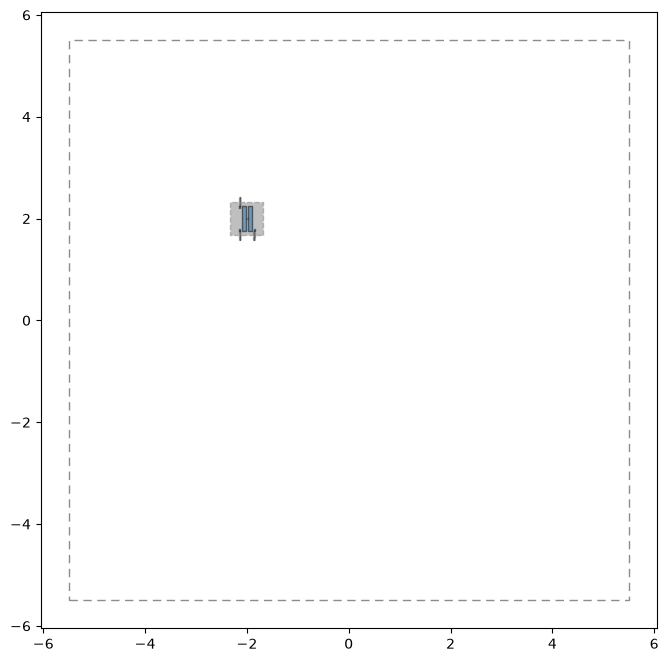

In [2]:
design = designs.DesignPlanar({}, overwrite_enabled=True)
design.delete_all_components()
design.overwrite_enabled = True

design.chips.main.size['size_x'] = '11mm'
design.chips.main.size['size_y'] = '11mm'

arm = "2 mm"
pad_opts = Dict(pad_width='50um', pad_height='30um', pad_gap='30um')

q0 = TransmonPocket6(design, 'Q0', options=Dict(
    pos_x=f'-{arm}', pos_y=f'{arm}', orientation=90, pad_width='500um', pocket_height='650um',
    connection_pads=Dict(
        to_Q4  =Dict(loc_W=-1, loc_H=-1, **pad_opts),
        to_Q2  =Dict(loc_W=-1, loc_H=+1, **pad_opts),
        readout=Dict(loc_W=+1, loc_H=+1, **pad_opts),
    )))
design.rebuild()

%matplotlib inline
view(design)

## 3. One shared mesh

The mesh is generated **once** and reused for every FE order, so that differences in the results are caused by the basis order alone and not by a different tessellation.

In [3]:
from pypalace import mesh

surface_table = mesh.get_quantum_metal_surfaces(design)

# give every etched ("subtract == False") surface a unique mesh attribute, as in the reference notebook
attributes, mesh_num = {}, 1
for row in range(len(surface_table)):
    r = surface_table.iloc[row]
    if r["subtract"] == False:
        attributes[(r["component_id"], r["name"])] = mesh_num
        mesh_num += 1

mesh_dir  = "mesh/"
meshfile  = "electrostatic_lom.msh"
path_to_mesh = mesh_dir + meshfile
os.makedirs(mesh_dir, exist_ok=True)

attributes_table = mesh.mesh_Quantum_Metal_design(design, output_mesh=path_to_mesh, Attributes=attributes)
attributes_table

Info    : Meshing 1D...nts                                                                                                                
Info    : [  0%] Meshing curve 25 (Line)
Info    : [ 10%] Meshing curve 26 (Line)
Info    : [ 10%] Meshing curve 27 (Line)
Info    : [ 10%] Meshing curve 28 (Line)
Info    : [ 10%] Meshing curve 29 (Line)
Info    : [ 10%] Meshing curve 30 (Line)
Info    : [ 10%] Meshing curve 31 (Line)
Info    : [ 10%] Meshing curve 32 (Line)
Info    : [ 10%] Meshing curve 33 (Line)
Info    : [ 10%] Meshing curve 34 (Line)
Info    : [ 20%] Meshing curve 35 (Line)
Info    : [ 20%] Meshing curve 36 (Line)
Info    : [ 20%] Meshing curve 37 (Line)
Info    : [ 20%] Meshing curve 38 (Line)
Info    : [ 20%] Meshing curve 39 (Line)
Info    : [ 20%] Meshing curve 40 (Line)
Info    : [ 20%] Meshing curve 41 (Line)
Info    : [ 20%] Meshing curve 42 (Line)
Info    : [ 20%] Meshing curve 43 (Line)
Info    : [ 20%] Meshing curve 44 (Line)
Info    : [ 30%] Meshing curve 45 (Line)


,Name,ID,Type
0,1__pad_top,1,Surface
11,air,10,Volume
8,ground_plane,11,Surface
9,far_field,12,Surface
1,1__pad_bot,2,Surface
2,1__to_Q4_connector_pad,3,Surface
3,1__to_Q2_connector_pad,4,Surface
4,1__readout_connector_pad,5,Surface
5,1__to_Q4_wire,6,Surface
6,1__to_Q2_wire,7,Surface


## 4. Palace configuration — one config per FE order

`build_config(order)` is the **only** place where the two setups differ: `Solver.Order` and the output directory/config filename (kept separate so neither run overwrites the other). Mesh attribute IDs are read from `attributes_table`, not hard-coded.

In [4]:
from pypalace import Config
from pypalace.builder import Model, Domains, Boundaries, Solver

# ------------------------------------------------------------------ user knobs
ORDERS          = [1, 2]       # FE orders to compare; the largest is the reference (e.g. [1, 2, 3])
MPI_PROCESSES   = 8
SAVE_FIELDS     = 5            # Paraview field dumps (set 0 to time the pure solve, then plot_field is unavailable)
LIN_TOL, LIN_MAXITS = 1e-10, 200
path_to_palace  = "/home/aashay2/spack/opt/spack/linux-zen4/palace-0.16.0-3aety6d23jpuyqhilcdu6q3di7icmlhf/bin/palace-x86_64.bin"
# -----------------------------------------------------------------------------

def _id(name):
    """Mesh attribute ID from the table returned by the mesher (suffix match, e.g. '1__pad_top')."""
    hit = attributes_table[attributes_table["Name"].str.endswith(name)]
    assert len(hit) == 1, f"attribute '{name}' not unique/found:\n{attributes_table}"
    return int(hit["ID"].iloc[0])

TERMINALS = ["pad_top", "pad_bot", "to_Q4_connector_pad", "to_Q2_connector_pad", "readout_connector_pad"]

def build_config(order, save=SAVE_FIELDS):
    tag = f"order{order}"
    cfg = Config(f"./electrostatic_lom_{tag}.json")
    cfg.add_Problem(Type="Electrostatic", Output=f"electrostatic_output_{tag}")
    cfg.add_Model(Mesh=path_to_mesh, L0=1e-6)

    silicon = Domains.Material(Attributes=[_id("substrate")], Permeability=1.0, Permittivity=11.45, LossTan=1e-07)
    airbox  = Domains.Material([_id("air")], 1.0, 1.0, 0.0)
    cfg.add_Domains(Materials=[silicon, airbox])

    grounds   = Boundaries.Ground(Attributes=[_id("ground_plane"), _id("far_field")])
    terminals = [Boundaries.Terminal(Index=i + 1, Attributes=[_id(n)]) for i, n in enumerate(TERMINALS)]
    cfg.add_Boundaries(BCs=[grounds] + terminals)

    cfg.add_Solver(Simulation=Solver.Electrostatic(Save=save),
                   Order=order,                                    # <-- the only physics/numerics difference
                   Linear=Solver.Linear(Type="BoomerAMG", KSPType="CG", Tol=LIN_TOL, MaxIts=LIN_MAXITS))
    cfg.save_config(check_validity=True)
    return cfg

configs = {p: build_config(p) for p in ORDERS}
for p in ORDERS:
    print(f"order {p}: Solver.Order =", json.load(open(f"electrostatic_lom_order{p}.json"))["Solver"]["Order"])

order 1: Solver.Order = 1
order 2: Solver.Order = 2


## 5. Run the electrostatic solves

Wall-clock time is measured around `Simulation.run` (includes mesh partitioning and, if `SAVE_FIELDS>0`, Paraview output). DOFs are read from Palace's `palace.json` when available (best effort; the key layout differs between Palace versions).

In [5]:
from pypalace import Simulation

def _find_key(obj, key):
    """Depth-first search for `key` in nested dict/list; returns first hit or None."""
    if isinstance(obj, dict):
        if key in obj: return obj[key]
        for v in obj.values():
            r = _find_key(v, key)
            if r is not None: return r
    elif isinstance(obj, list):
        for v in obj:
            r = _find_key(v, key)
            if r is not None: return r
    return None

sims, run_info = {}, {}
for p in ORDERS:
    sims[p] = Simulation(configs[p], path_to_palace)
    t0 = time.perf_counter()
    sims[p].run(n=MPI_PROCESSES)
    wall = time.perf_counter() - t0

    dofs = None
    for f in glob.glob(f"electrostatic_output_order{p}/palace.json"):
        try: dofs = _find_key(json.load(open(f)), "DegreesOfFreedom")
        except Exception: pass
    run_info[p] = {"FE order p": p, "wall time [s]": wall, "DOFs (H1)": dofs}

run_table = pd.DataFrame(run_info).T.set_index("FE order p")
run_table

Authorization required, but no authorization protocol specified
Authorization required, but no authorization protocol specified

_____________     _______
_____   __   \____ __   /____ ____________
____   /_/  /  __ ` /  /  __ ` /  ___/  _ \
___   _____/  /_/  /  /  /_/  /  /__/  ___/
  /__/     \___,__/__/\___,__/\_____\_____/

Git changeset ID: 869ee5c
Running with 8 MPI processes
Device configuration: cpu
Memory configuration: host-std
libCEED backend: /cpu/self/xsmm/blocked

Added 751 duplicate vertices for interior boundaries in the mesh
Added 2010 duplicate boundary elements for interior boundaries in the mesh
Added 13853 boundary elements for material interfaces to the mesh
Finished partitioning mesh into 8 subdomains

Characteristic length and time scales:
 Lc = 1.850e-03 m, tc = 6.171e-03 ns

Mesh curvature order: 1
Mesh bounding box:
 (Xmin, Ymin, Zmin) = (-2.825e-03, +1.075e-03, -5.000e-04) m
 (Xmax, Ymax, Zmax) = (-1.175e-03, +2.925e-03, +5.000e-04) m

Parallel Mesh Stats:


,wall time [s],DOFs (H1)
FE order p,,
1.0,3.743626,17507.0
2.0,12.008260,124926.0


## 6. Capacitance matrices

Extraction and reordering follow the reference notebook (`ground` first). The matrices are **not** modified here; symmetrisation, where needed for the LOM input, is done (and reported) in §7.

In [6]:
GROUP_ORDER = ["ground", "pad_top", "pad_bot", "to_Q4_connector_pad", "to_Q2_connector_pad", "readout_connector_pad"]

def clean_cmat(df):
    df = df.copy()
    df.columns = [c.replace("1__", "") for c in df.columns]
    df.index   = [c.replace("1__", "") for c in df.index]
    return df.reindex(index=GROUP_ORDER, columns=GROUP_ORDER)

cmats = {p: clean_cmat(sims[p].get_capacitance_matrix()) for p in ORDERS}
REF = max(ORDERS)
print(f"Reference order: p = {REF}")
cmats[REF]

Reference order: p = 2


,ground,pad_top,pad_bot,to_Q4_connector_pad,to_Q2_connector_pad,readout_connector_pad
ground,0.000000e+00,-5.397485e-14,-5.641789e-14,-7.011212e-15,-7.088929e-15,-7.042519e-15
pad_top,-5.397485e-14,1.022380e-13,-3.861324e-14,-4.590967e-16,-4.614832e-15,-4.575963e-15
pad_bot,-5.641789e-14,-3.861324e-14,1.005504e-13,-4.578583e-15,-4.686493e-16,-4.720268e-16
to_Q4_connector_pad,-7.011212e-15,-4.590967e-16,-4.578583e-15,1.208308e-14,-2.873771e-17,-5.451861e-18
to_Q2_connector_pad,-7.088929e-15,-4.614832e-15,-4.686493e-16,-2.873771e-17,1.221979e-14,-1.864606e-17
readout_connector_pad,-7.042519e-15,-4.575963e-15,-4.720268e-16,-5.451861e-18,-1.864606e-17,1.211461e-14


### 6.1 Raw matrix comparison

For $\Delta C_{ij}=C^{(p)}_{ij}-C^{(\rm ref)}_{ij}$ we report the absolute difference in **aF** (robust for the tiny off-diagonals) and the relative difference in % (meaningful only for entries that are not close to zero). We also check basic physical consistency: symmetry $\max|C_{ij}-C_{ji}|/\max|C|$ and the Maxwell row-sum rule $\sum_j C_{ij}=0$ for non-ground rows.

                         p=1      p=2
max asymmetry (rel) 0.00e+00 0.00e+00
max |row sum| (rel) 1.28e-16 4.63e-17


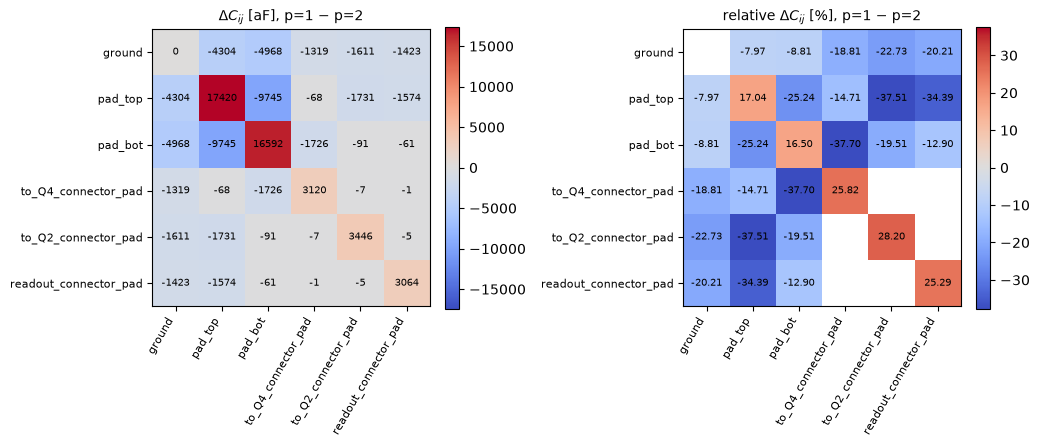

In [7]:
def consistency(C):
    M = C.to_numpy(dtype=float)
    asym = np.max(np.abs(M - M.T)) / np.max(np.abs(M))
    ng = [i for i, n in enumerate(C.index) if n != "ground"]
    rowsum = np.max(np.abs(M[ng].sum(axis=1))) / np.max(np.abs(M))
    return {"max asymmetry (rel)": asym, "max |row sum| (rel)": rowsum}

print(pd.DataFrame({f"p={p}": consistency(cmats[p]) for p in ORDERS}).to_string(float_format=lambda x: f"{x:.2e}"))

fig, axes = plt.subplots(1, 2 * (len(ORDERS) - 1), figsize=(7.5 * (len(ORDERS) - 1) * 2 / 2 + 3, 4.8), squeeze=False)
axes = axes[0]
k = 0
for p in ORDERS:
    if p == REF: continue
    D_aF = (cmats[p] - cmats[REF]) * 1e18
    with np.errstate(divide="ignore", invalid="ignore"):
        D_pc = 100 * (cmats[p] - cmats[REF]) / cmats[REF].abs()
    # relative error only where the reference entry is non-negligible (> 0.1 % of the largest entry)
    mask = cmats[REF].abs() < 1e-3 * cmats[REF].abs().to_numpy().max()
    D_pc = D_pc.mask(mask)

    for ax, Dm, ttl, fmt in ((axes[k], D_aF, f"$\\Delta C_{{ij}}$ [aF], p={p} − p={REF}", "{:.0f}"),
                             (axes[k + 1], D_pc, f"relative $\\Delta C_{{ij}}$ [%], p={p} − p={REF}", "{:.2f}")):
        im = ax.imshow(Dm.to_numpy(dtype=float), cmap="coolwarm",
                       vmin=-np.nanmax(np.abs(Dm.to_numpy(dtype=float))), vmax=np.nanmax(np.abs(Dm.to_numpy(dtype=float))))
        ax.set_xticks(range(len(Dm))); ax.set_xticklabels(Dm.columns, rotation=60, ha="right", fontsize=8)
        ax.set_yticks(range(len(Dm))); ax.set_yticklabels(Dm.index, fontsize=8)
        for i in range(len(Dm)):
            for j in range(len(Dm)):
                v = Dm.iat[i, j]
                if np.isfinite(v): ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=7)
        ax.set_title(ttl, fontsize=10); plt.colorbar(im, ax=ax, fraction=0.046)
    k += 2
plt.tight_layout(); plt.show()

## 7. LOM Hamiltonian extraction

`extract_lom_hamiltonian` is copied **unchanged** from the reference notebook (it mirrors `extract_transmon_coupled_Noscillator`). It is called once per FE order with identical $L_J$, $C_J$, $f_r$, $f_b$.

Because it enforces $C=C^{\mathsf T}$ to a relative tolerance of $10^{-3}$, we symmetrise $C\leftarrow\tfrac12(C+C^{\mathsf T})$ before the call; the asymmetry removed is printed so that it is visible rather than hidden. Palace's matrix is typically symmetric to solver tolerance, so this is a no-op in practice.

In [8]:
import numpy as np
import pandas as pd


def extract_lom_hamiltonian(
    cmat, Ic, CJ, fr, fb,
    labels=None,
    ground="ground",
    qubit_pads=("pad_top", "pad_bot"),
    readout="readout_connector_pad",
    buses=None,
    res_L4_corr=None,
    g_scale=1.0,
    Z0=50.0,
    ng_points=51,
    nmax=40,
    use_metal_constants=True,
    print_info=False,
):
    """Monolithic LOM extraction: floating two-pad transmon + N coupling pads.

    Mirrors qiskit_metal.analyses.quantization.lumped_capacitive
    .extract_transmon_coupled_Noscillator, but reads node names, reorders the
    Maxwell matrix itself, and has no qiskit_metal dependency.

    cmat   : DataFrame (labelled) or ndarray + labels; Maxwell matrix in FARADS.
    Ic     : junction critical current [A];  CJ : junction capacitance [F]
    fr     : readout resonator frequency [GHz]
    fb     : bus resonator frequencies [GHz], order of `buses`
    buses  : bus coupling-pad names (default: all remaining nodes, matrix order)
    res_L4_corr : per resonator [readout, bus1, ...]; 1 -> lambda/4
    use_metal_constants : True -> CODATA-2014 values used inside qiskit-metal.
    """
    # ---------------------------------------------------------------- constants
    if use_metal_constants:
        e, h, hbar = 1.60217657e-19, 6.62606957e-34, 1.0545718e-34
        phi0 = 2.067e-15 / (2 * np.pi)                   # reduced flux quantum
    else:
        e, h = 1.602176634e-19, 6.62607015e-34
        hbar = h / (2 * np.pi)
        phi0 = hbar / (2 * e)

    # ---------------------------------------------------------------- parse + reorder
    if isinstance(cmat, pd.DataFrame):
        names, C = list(cmat.index), cmat.to_numpy(dtype=float)
    else:
        if labels is None:
            raise ValueError("labels is required when cmat is not a DataFrame")
        names, C = list(labels), np.asarray(cmat, dtype=float)
    if C.shape != (len(names), len(names)):
        raise ValueError(f"cmat shape {C.shape} does not match {len(names)} labels")
    if not np.allclose(C, C.T, rtol=1e-3, atol=1e-20):
        raise ValueError("Capacitance matrix is not symmetric")
    # Maxwell matrix: every non-ground row sums to ~0 (Q3D leaves the ground diagonal at 0)
    ng_rows = [i for i, nm in enumerate(names) if nm != ground]
    if not np.allclose(C[ng_rows].sum(axis=1), 0, atol=1e-3 * np.abs(np.diag(C)).max()):
        raise ValueError("Non-ground rows do not sum to ~0: not a Maxwell capacitance matrix")

    qubit_pads = list(qubit_pads)
    if buses is None:
        buses = [n for n in names if n not in (ground, readout, *qubit_pads)]
    buses = list(buses)
    N = 1 + len(buses)                                   # 1 readout + (N-1) buses
    order = buses + [ground] + qubit_pads + [readout]    # qiskit-metal basis
    if sorted(order) != sorted(names):
        raise ValueError(f"Node-name mismatch. Matrix has {names}; expected {order}")
    idx = [names.index(n) for n in order]
    CM = C[np.ix_(idx, idx)]
    res_names = [readout] + buses                        # output order [readout, bus1, ...]

    fb_list = [fb] * (N - 1) if np.isscalar(fb) else list(fb)
    if len(fb_list) != N - 1:
        raise ValueError(f"fb needs {N-1} entries (one per bus), got {len(fb_list)}")
    wr = 2 * np.pi * 1e9 * np.array([fr] + fb_list, dtype=float)       # rad/s

    # ---------------------------------------------------------------- resonator LC
    Cr = 0.5 * np.pi / (wr * Z0)                         # lambda/2 equivalent
    Lr = 1.0 / (wr**2 * Cr)
    if res_L4_corr is not None:
        for i, flag in enumerate(res_L4_corr):
            if flag:
                Cr[i] /= 2.0
                Lr[i] *= 2.0

    # ---------------------------------------------------------------- capacitance bookkeeping
    g_i = N - 1
    q_i = [g_i + 1, g_i + 2]
    r_i = [len(CM) - 1] + list(range(N - 1))             # [readout, bus1, ...]

    Cg = np.array([-CM[q_i[0], g_i], -CM[q_i[1], g_i]])
    Cs = -CM[q_i[0], q_i[1]]
    Cbus = np.array([[-CM[q, r] for r in r_i] for q in q_i])            # (2, N)
    Cbb = np.array([[-CM[a, b] if a != b else 0.0 for b in r_i] for a in r_i])

    C1S = Cg[0] + Cbus[0].sum()
    C2S = Cg[1] + Cbus[1].sum()
    tCSq = Cs + C1S * C2S / (C1S + C2S)
    tCSbus = (Cr - (Cbus[0] + Cbus[1])**2 / (C1S + C2S)
              + Cbus.sum(axis=0) + Cbb.sum(axis=1))
    tCqbus = (C2S * Cbus[0] - Cbus[1] * C1S) / (C1S + C2S)
    tCqbb = Cbb + np.outer(Cbus[0] + Cbus[1], Cbus[0] + Cbus[1]) / (C1S + C2S)
    bbus = (C2S * Cbus[0] - Cbus[1] * C1S) / ((C1S + C2S) * Cs + C1S * C2S)
    Cq = tCSq + CJ

    # ---------------------------------------------------------------- transmon
    LJ = phi0 / Ic
    EJ = phi0**2 / LJ / hbar                             # rad/s
    EC = e**2 / (2 * Cq) / hbar                          # rad/s
    Zqp = np.sqrt(LJ / Cq)

    Ec_J, EJ_J = e**2 / (2 * Cq), Ic * hbar / (2 * e)
    n = np.arange(-nmax, nmax + 1)
    V = -0.5 * (np.eye(len(n), k=1) + np.eye(len(n), k=-1))
    E = np.array([np.linalg.eigvalsh(4 * Ec_J * np.diag((n - ng)**2) + EJ_J * V)[:3]
                  for ng in np.linspace(-1, 1, ng_points)])
    E = E - E[:, [0]]
    fq_Hz = np.mean(E[:, 1]) / h
    alpha_Hz = np.mean(E[:, 2] - 2 * E[:, 1]) / h
    disp_Hz = np.max(-E[:, 1] / h + E[0, 1] / h)
    wq = 2 * np.pi * fq_Hz
    alpha_rad = 2 * np.pi * alpha_Hz

    # ---------------------------------------------------------------- couplings
    Zbus = np.sqrt(Lr / tCSbus)
    gq = 0.5 * wr * bbus * np.sqrt(Zbus / Zqp) * g_scale                # rad/s
    gbb = 0.5 * np.sqrt(np.outer(wr, wr)) * tCqbb / np.sqrt(np.outer(tCSbus, tCSbus))
    np.fill_diagonal(gbb, 0.0)

    # ---------------------------------------------------------------- dispersive shift (Koch)
    w01, w12 = wq, wq + alpha_rad
    chi0 = -2 * gq**2 * w01 / (w01**2 - wr**2)
    chi1 = gq**2 * (1 / (w01 - wr) - 2 / (w12 - wr) + 1 / (w01 + wr) - 2 / (w12 + wr))
    chi_MHz = (chi1 - chi0) / (2 * np.pi * 1e6)          # full |0>->|1> splitting

    # ---------------------------------------------------------------- Purcell (same Q guesses as reference)
    Qres = np.full(N, 1e5)
    Qres[0] = 1e4
    kappa = wr / Qres
    T1bus = (wr**2 - wq**2)**2 / (4 * kappa * gq**2 * wq**2)
    T1 = 1.0 / np.sum(1.0 / T1bus)

    # ---------------------------------------------------------------- pack
    MHz = 2 * np.pi * 1e6
    out = {
        "fQ": fq_Hz / 1e9,                  # GHz
        "EC": EC / MHz,                     # MHz
        "EJ": EJ / (2 * np.pi * 1e9),       # GHz
        "alpha": alpha_Hz / 1e6,            # MHz
        "dispersion": disp_Hz / 1e3,        # kHz
        "gbus": gq / MHz,                   # MHz, order = res_names
        "chi_in_MHz": chi_MHz,              # MHz, order = res_names
        # extras (not in the qiskit-metal dict)
        "res_names": res_names,
        "Cq_fF": Cq * 1e15,
        "LJ_nH": LJ * 1e9,
        "tCqbus_fF": tCqbus * 1e15,
        "T1_purcell_us": T1 * 1e6,
        "g_res_res_MHz": pd.DataFrame(gbb / MHz, index=res_names, columns=res_names),
        "summary": pd.DataFrame(
            {"f_res [GHz]": wr / (2 * np.pi * 1e9), "g [MHz]": gq / MHz,
             "chi [MHz]": chi_MHz, "Cqc [fF]": tCqbus * 1e15,
             "T1_Purcell [us]": T1bus * 1e6}, index=res_names),
    }
    if print_info:
        print(f"fQ = {out['fQ']:.4f} GHz | EC = {out['EC']:.2f} MHz | EJ = {out['EJ']:.3f} GHz | "
              f"alpha = {out['alpha']:.2f} MHz | Cq = {out['Cq_fF']:.3f} fF | "
              f"LJ = {out['LJ_nH']:.3f} nH | charge disp = {out['dispersion']:.3g} kHz | "
              f"T1(Purcell) = {out['T1_purcell_us']:.1f} us")
        print(out["summary"].round(4).to_string())
        print("\nresonator-resonator g [MHz]:")
        print(out["g_res_res_MHz"].round(4).to_string())
    return out

In [9]:
from pint import UnitRegistry
from qiskit_metal.analyses.quantization.constants import Ic_from_Lj
ureg = UnitRegistry()

lom_setup = Dict(junctions=Dict(Lj=12, Cj=2), freq_readout=7.0, freq_bus=[6.0, 6.2])   # same as reference notebook
BUSES = ["to_Q4_connector_pad", "to_Q2_connector_pad"]

ic_amps = Ic_from_Lj(lom_setup.junctions.Lj, "nH", "A")
cj      = ureg(f"{lom_setup.junctions.Cj} fF").to("farad").magnitude
fread   = lom_setup.freq_readout
fbus    = list(lom_setup.freq_bus)

def symmetrised(C):
    M = C.to_numpy(dtype=float)
    asym = np.max(np.abs(M - M.T))
    return pd.DataFrame(0.5 * (M + M.T), index=C.index, columns=C.columns), asym

hams = {}
for p in ORDERS:
    Csym, asym = symmetrised(cmats[p])
    print(f"p={p}: symmetrised away max |C_ij - C_ji| = {asym:.2e} F")
    hams[p] = extract_lom_hamiltonian(Csym, Ic=ic_amps, CJ=cj, fr=fread, fb=fbus, buses=BUSES, print_info=False)
    print(f"----- LOM, p={p} -----")
    print(f"fQ = {hams[p]['fQ']:.4f} GHz | EC = {hams[p]['EC']:.2f} MHz | alpha = {hams[p]['alpha']:.2f} MHz | Cq = {hams[p]['Cq_fF']:.3f} fF")

p=1: symmetrised away max |C_ij - C_ji| = 0.00e+00 F
----- LOM, p=1 -----
fQ = 4.7328 GHz | EC = 226.90 MHz | alpha = -256.76 MHz | Cq = 85.368 fF
p=2: symmetrised away max |C_ij - C_ji| = 0.00e+00 F
----- LOM, p=2 -----
fQ = 5.1290 GHz | EC = 269.04 MHz | alpha = -308.69 MHz | Cq = 71.998 fF


## 8. Hamiltonian-parameter comparison

### 8.1 Qubit parameters

In [10]:
TOL_PCT = 1.0     # tolerance (%) used for the verdict at the end

def scalar_params(h):
    return {
        "f01 [GHz]":              h["fQ"],
        "E_C [MHz]":              h["EC"],
        "E_J [GHz]":              h["EJ"],
        "E_J/E_C":                h["EJ"] * 1e3 / h["EC"],
        "alpha [MHz]":            h["alpha"],
        "charge dispersion [kHz]": h["dispersion"],
        "C_q (incl. C_J) [fF]":   h["Cq_fF"],
        "T1 Purcell [us]":        h["T1_purcell_us"],
    }

scal = pd.DataFrame({f"p={p}": scalar_params(hams[p]) for p in ORDERS})
for p in ORDERS:
    if p == REF: continue
    scal[f"Δ (p={p} − p={REF})"]  = scal[f"p={p}"] - scal[f"p={REF}"]
    scal[f"Δ% (p={p} vs p={REF})"] = 100 * scal[f"Δ (p={p} − p={REF})"] / scal[f"p={REF}"].abs()
scal.style.format("{:.5g}")

,p=1,p=2,Δ (p=1 − p=2),Δ% (p=1 vs p=2)
f01 [GHz],4.7328,5.129,-0.39616,-7.7239
E_C [MHz],226.9,269.04,-42.135,-15.661
E_J [GHz],13.611,13.611,0,0
E_J/E_C,59.985,50.591,9.3945,18.57
alpha [MHz],-256.76,-308.69,51.924,16.821
charge dispersion [kHz],1.6928,9.5568,-7.8639,-82.287
C_q (incl. C_J) [fF],85.368,71.998,13.37,18.57
T1 Purcell [us],1077.7,868.27,209.45,24.123


### 8.2 Per-resonator parameters ($g$, $\chi$, $\tilde C_{qk}$, Purcell $T_1$)

In [11]:
res_tabs = {p: hams[p]["summary"] for p in ORDERS}
res_all  = pd.concat(res_tabs, axis=1)           # columns: (p, quantity)
res_all

1                                 \
                      f_res [GHz]    g [MHz] chi [MHz]  Cqc [fF]   
readout_connector_pad         7.0  33.544947 -0.105275  2.748349   
to_Q4_connector_pad           6.0 -30.875961 -0.257866 -2.950484   
to_Q2_connector_pad           6.2  30.608071 -0.194330  2.830791   

                                                2                       \
                      T1_Purcell [us] f_res [GHz]    g [MHz] chi [MHz]   
readout_connector_pad     1595.664847         7.0  28.127772 -0.123176   
to_Q4_connector_pad       5744.171023         6.0 -25.018186 -0.379272   
to_Q2_connector_pad       7868.345804         6.2  25.175430 -0.267935   

                                                 
                       Cqc [fF] T1_Purcell [us]  
readout_connector_pad  2.018045     1406.475355  
to_Q4_connector_pad   -2.093597     3784.399021  
to_Q2_connector_pad    2.038929     5666.632292

In [12]:
rows = []
for p in ORDERS:
    if p == REF: continue
    d = 100 * (res_tabs[p] - res_tabs[REF]) / res_tabs[REF].abs()
    d.columns = [f"Δ% {c}" for c in d.columns]
    d.insert(0, "p", p)
    rows.append(d)
res_rel = pd.concat(rows) if rows else pd.DataFrame()
res_rel.style.format({c: "{:.4g}" for c in res_rel.columns if c != "p"})

,p,Δ% f_res [GHz],Δ% g [MHz],Δ% chi [MHz],Δ% Cqc [fF],Δ% T1_Purcell [us]
readout_connector_pad,1,0,19.26,14.53,36.19,13.45
to_Q4_connector_pad,1,0,-23.41,32.01,-40.93,51.79
to_Q2_connector_pad,1,0,21.58,27.47,38.84,38.85


### 8.3 Resonator–resonator coupling $g_{rr}$ [MHz]

In [13]:
for p in ORDERS:
    if p == REF: continue
    d = hams[p]["g_res_res_MHz"] - hams[REF]["g_res_res_MHz"]
    print(f"Δ g_rr [MHz]  (p={p} − p={REF})"); display(d.round(5))

Δ g_rr [MHz]  (p=1 − p=2)


,readout_connector_pad,to_Q4_connector_pad,to_Q2_connector_pad
readout_connector_pad,0.00000,0.51495,0.55760
to_Q4_connector_pad,0.51495,0.00000,0.51501
to_Q2_connector_pad,0.55760,0.51501,0.00000


## 9. Visual comparison

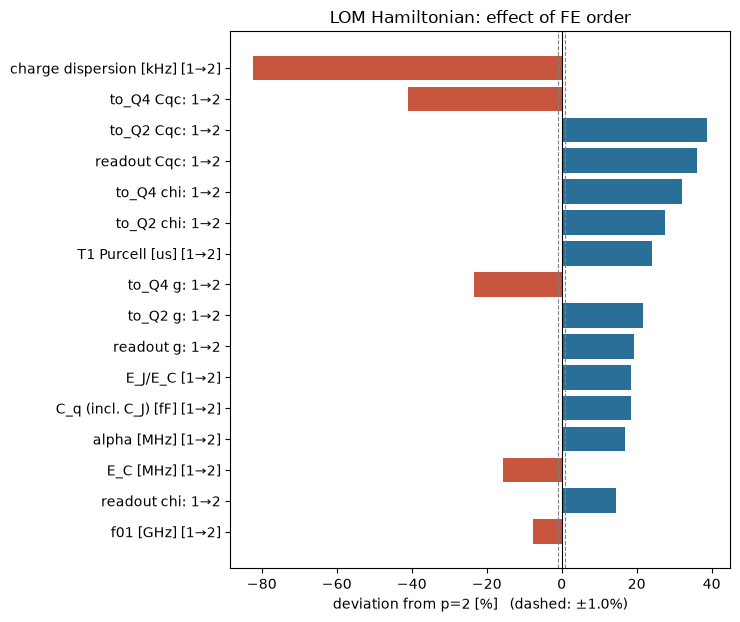

In [14]:
# (a) % deviation from the reference, all Hamiltonian quantities
dev = {}
for p in ORDERS:
    if p == REF: continue
    s = scal[f"Δ% (p={p} vs p={REF})"].drop(["E_J [GHz]"], errors="ignore")      # E_J is input-only (no EM dependence)
    dev[f"qubit: {p}→{REF}"] = s
    r = res_rel[res_rel["p"] == p].drop(columns="p")
    for q in ["g [MHz]", "chi [MHz]", "Cqc [fF]"]:
        for name in r.index:
            dev[f"{name.replace('_connector_pad','')} {q.split()[0]}: {p}→{REF}"] = pd.Series({q: r.loc[name, f"Δ% {q}"]})

if dev:
    flat = {}
    for k, v in dev.items():
        for idx, val in v.items():
            flat[f"{idx} [{k.split(':')[-1].strip()}]" if k.startswith("qubit") else k] = val
    ser = pd.Series(flat).sort_values(key=np.abs)
    fig, ax = plt.subplots(figsize=(7.5, 0.32 * len(ser) + 1.2))
    ax.barh(ser.index, ser.values, color=np.where(ser.values >= 0, "#2a6f97", "#c8553d"))
    ax.axvline(0, color="k", lw=0.8)
    for x in (-TOL_PCT, TOL_PCT): ax.axvline(x, color="gray", ls="--", lw=0.8)
    ax.set_xlabel(f"deviation from p={REF} [%]   (dashed: ±{TOL_PCT}%)")
    ax.set_title("LOM Hamiltonian: effect of FE order")
    plt.tight_layout(); plt.show()

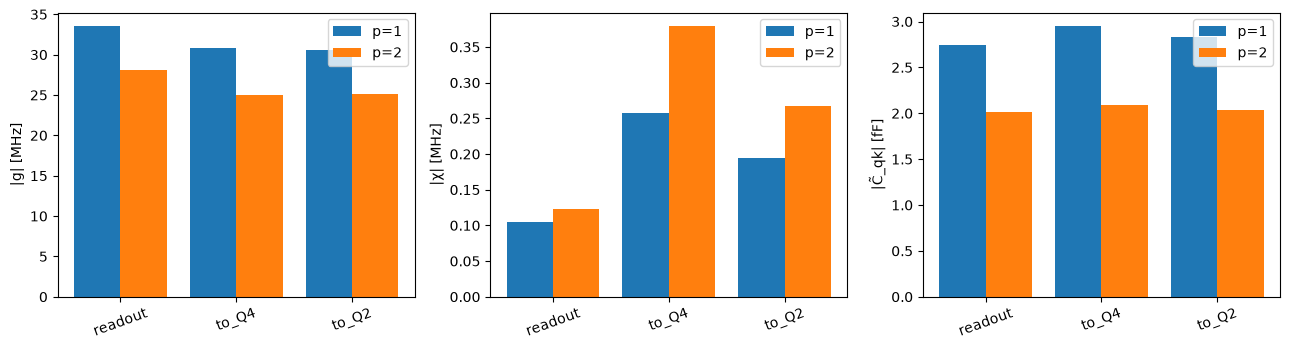

In [15]:
# (b) side-by-side absolute values per resonator
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
names = hams[REF]["res_names"]; x = np.arange(len(names)); w = 0.8 / len(ORDERS)
for ax, (key, lab) in zip(axes, [("g [MHz]", "|g| [MHz]"), ("chi [MHz]", "|χ| [MHz]"), ("Cqc [fF]", "|C̃_qk| [fF]")]):
    for i, p in enumerate(ORDERS):
        ax.bar(x + i * w, np.abs(res_tabs[p][key].to_numpy()), w, label=f"p={p}")
    ax.set_xticks(x + w * (len(ORDERS) - 1) / 2); ax.set_xticklabels([n.replace("_connector_pad", "") for n in names], rotation=20)
    ax.set_ylabel(lab); ax.legend()
plt.tight_layout(); plt.show()

## 10. Consistency check against first-order error propagation (§1.3)

If the only significant effect of the FE order on the qubit were the shift of $C_q$, the observed $\delta f_{01}$ and $\delta\alpha$ should follow

$$
\delta f_{01}\simeq-\big(\sqrt{2E_JE_C}-E_C\big)\frac{\delta C_q}{C_q},\qquad
\delta\alpha\simeq+E_C\frac{\delta C_q}{C_q}.
$$

Agreement is expected to within a few % for $f_{01}$; for $\alpha$ the leading term $-E_C$ ignores the $\mathcal{O}(E_C^{3/2}/E_J^{1/2})$ correction, so a ~10–20 % mismatch there is normal. A much larger mismatch would indicate that something other than $C_q$ (e.g. asymmetry-sensitive terms) is driving the change.

In [16]:
ref = hams[REF]
EC_GHz, EJ_GHz = ref["EC"] / 1e3, ref["EJ"]
rows = {}
for p in ORDERS:
    if p == REF: continue
    dCq_rel = (hams[p]["Cq_fF"] - ref["Cq_fF"]) / ref["Cq_fF"]
    rows[f"p={p}"] = {
        "δC_q/C_q [%]":              100 * dCq_rel,
        "δf01 observed [MHz]":       1e3 * (hams[p]["fQ"] - ref["fQ"]),
        "δf01 predicted [MHz]":      1e3 * (-(np.sqrt(2 * EJ_GHz * EC_GHz) - EC_GHz) * dCq_rel),
        "δα observed [MHz]":         hams[p]["alpha"] - ref["alpha"],
        "δα predicted [MHz]":        EC_GHz * 1e3 * dCq_rel,
    }
pd.DataFrame(rows).style.format("{:.4g}")

,p=1
δC_q/C_q [%],18.57
δf01 observed [MHz],-396.2
δf01 predicted [MHz],-452.6
δα observed [MHz],51.92
δα predicted [MHz],49.96


## 11. Summary

In [17]:
# automatic verdict: worst-case relative deviation per group, p -> reference
print(f"Reference: p = {REF}   |   tolerance: {TOL_PCT:.2f} %\n")
print(run_table.to_string(), "\n")
for p in ORDERS:
    if p == REF: continue
    q_dev = scal[f"Δ% (p={p} vs p={REF})"].drop(["E_J [GHz]", "charge dispersion [kHz]"], errors="ignore").abs()
    r_dev = res_rel[res_rel["p"] == p].drop(columns="p").abs()
    print(f"p={p} vs p={REF}")
    print(f"  qubit (f01, E_C, alpha, C_q, T1)   : worst = {q_dev.max():.3f} %  ({q_dev.idxmax()})")
    print(f"  resonator (g, chi, C_qk, T1_Purcell): worst = {r_dev.to_numpy().max():.3f} %")
    cap = 100 * np.abs((cmats[p] - cmats[REF]).to_numpy()).max() / np.abs(cmats[REF].to_numpy()).max()
    print(f"  capacitance matrix (max |ΔC| / max|C|): {cap:.3f} %")
    ok_q, ok_r = q_dev.max() < TOL_PCT, r_dev.to_numpy().max() < TOL_PCT
    print("  verdict:", "within tolerance for qubit AND couplings" if ok_q and ok_r else
          "qubit parameters within tolerance, couplings/dispersive terms are NOT" if ok_q else
          "outside tolerance -> use the higher order (or refine the mesh)")

Reference: p = 2   |   tolerance: 1.00 %

            wall time [s]  DOFs (H1)
FE order p                          
1.0              3.743626    17507.0
2.0             12.008260   124926.0 

p=1 vs p=2
  qubit (f01, E_C, alpha, C_q, T1)   : worst = 24.123 %  (T1 Purcell [us])
  resonator (g, chi, C_qk, T1_Purcell): worst = 51.786 %
  capacitance matrix (max |ΔC| / max|C|): 17.039 %
  verdict: outside tolerance -> use the higher order (or refine the mesh)


In [18]:
# persist results for later notebooks / reports
out = {"orders": ORDERS, "reference": REF,
       "run": run_table.reset_index().to_dict(orient="list"),
       "scalar": scal.to_dict(),
       "per_resonator": {str(p): res_tabs[p].to_dict() for p in ORDERS}}
json.dump(out, open("fe_order_comparison_results.json", "w"), indent=2, default=float)
scal.to_csv("fe_order_comparison_qubit.csv")
for p in ORDERS: cmats[p].to_csv(f"cmat_order{p}.csv")